In [144]:
import pandas as pd
import numpy as np

print("Portuguese Bank Marketing Project")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Portuguese Bank Marketing Project
Pandas: 3.0.5
NumPy: 2.5.2


In [145]:
df = pd.read_csv("../data/bank-additional-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 41188
Columns: 21


In [146]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [147]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [148]:
df["y"].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [149]:
df["y"].value_counts(normalize=True) * 100

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64

In [150]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [151]:
df.duplicated().sum()

np.int64(12)

In [152]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Rows after removing duplicates:", df.shape[0])

Duplicates removed successfully!
Rows after removing duplicates: 41176


In [153]:
df.duplicated().sum()

np.int64(0)

In [154]:
df.to_csv("../data/bank_marketing_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [155]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,10.42068,259.305321,2.770318,186.937102,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [156]:
print("JOB")
print(df["job"].value_counts())

print("\nEDUCATION")
print(df["education"].value_counts())

print("\nMARITAL STATUS")
print(df["marital"].value_counts())

JOB
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

EDUCATION
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

MARITAL STATUS
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64


In [157]:
job_success = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_success = job_success.sort_values("yes", ascending=False)

job_success

y,no,yes
job,,
student,68.571429,31.428571
retired,74.738068,25.261932
unemployed,85.798817,14.201183
admin.,87.033305,12.966695
management,88.782490,11.217510
unknown,88.787879,11.212121
technician,89.167532,10.832468
self-employed,89.514426,10.485574
housemaid,90.000000,10.000000


In [158]:
education_success = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_success = education_success.sort_values("yes", ascending=False)

education_success

y,no,yes
education,,
illiterate,77.777778,22.222222
unknown,85.491329,14.508671
university.degree,86.279184,13.720816
professional.course,88.645038,11.354962
high.school,89.161060,10.838940
basic.4y,89.750958,10.249042
basic.6y,91.793976,8.206024
basic.9y,92.175352,7.824648


In [159]:
marital_success = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

marital_success = marital_success.sort_values("yes", ascending=False)

marital_success

y,no,yes
marital,,
unknown,85.000000,15.000000
single,85.991007,14.008993
divorced,89.676860,10.323140
married,89.843907,10.156093


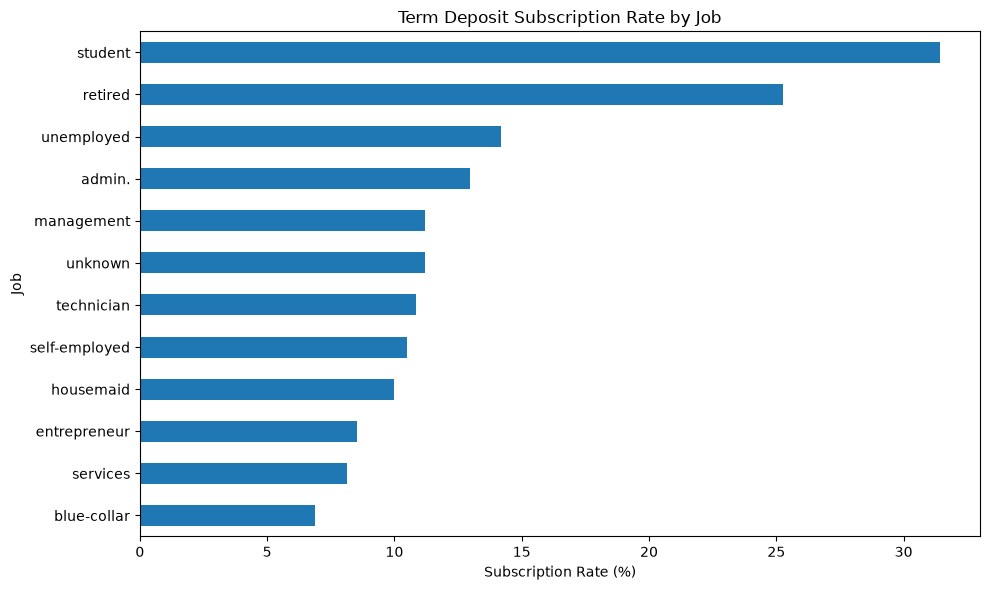

In [160]:
import matplotlib.pyplot as plt

job_success["yes"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

In [161]:
import sys
print(sys.executable)

c:\Users\hp\AppData\Local\Programs\Python\Python313\python.exe


In [162]:
import sys
print(sys.executable)

c:\Users\hp\AppData\Local\Programs\Python\Python313\python.exe


In [163]:
import matplotlib
print("Matplotlib:", matplotlib.__version__)

Matplotlib: 3.11.2


In [164]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [165]:
import matplotlib
print("Matplotlib:", matplotlib.__version__)

Matplotlib: 3.11.2


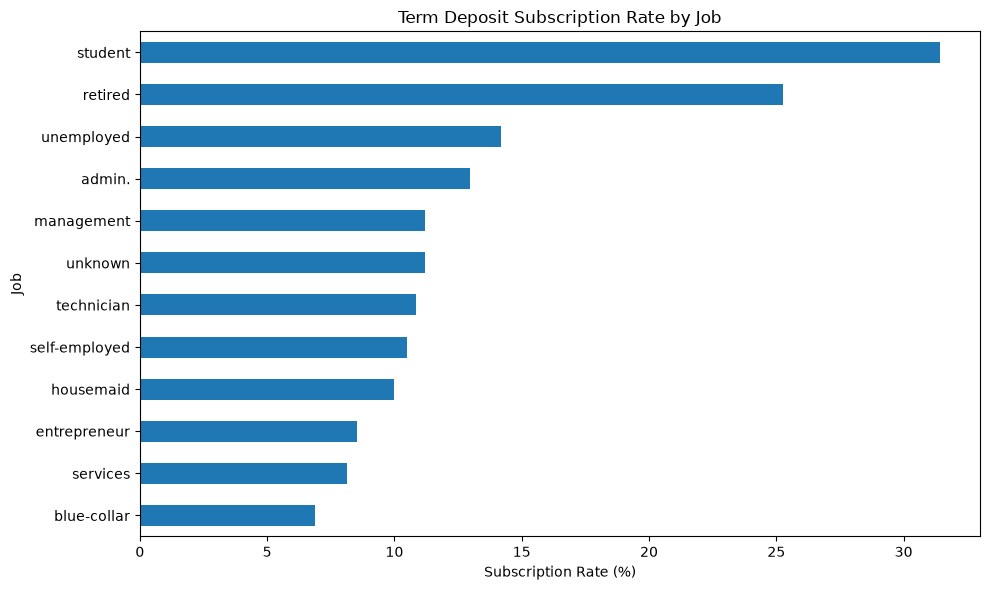

In [166]:
import matplotlib.pyplot as plt

job_success["yes"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

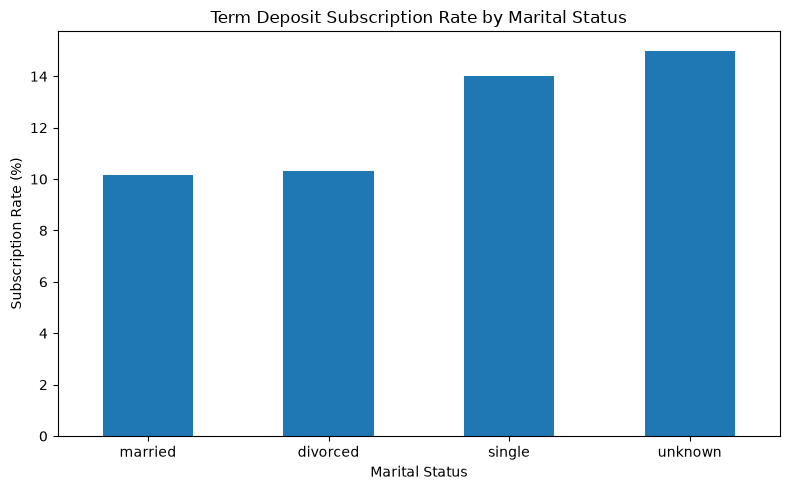

In [167]:
marital_success = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

marital_success["yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

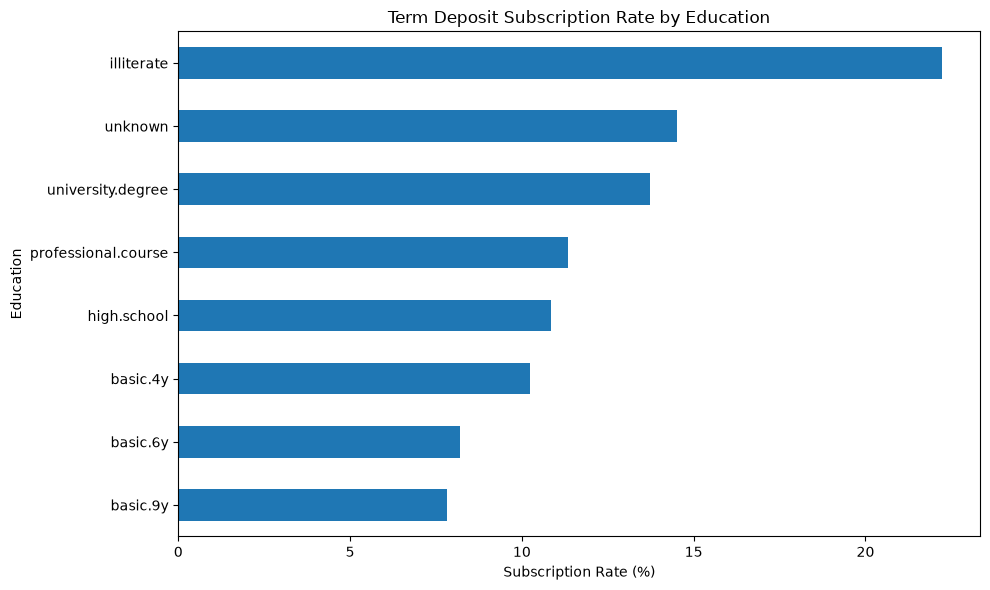

In [168]:
education_success = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_success["yes"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education")
plt.tight_layout()
plt.show()

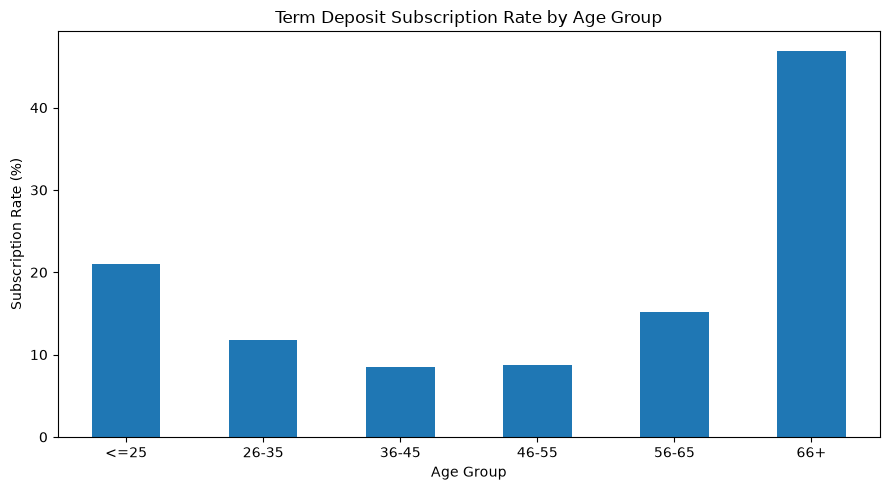

In [169]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["<=25", "26-35", "36-45", "46-55", "56-65", "66+"]
)

age_success = pd.crosstab(
    df["age_group"],
    df["y"],
    normalize="index"
) * 100

age_success["yes"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

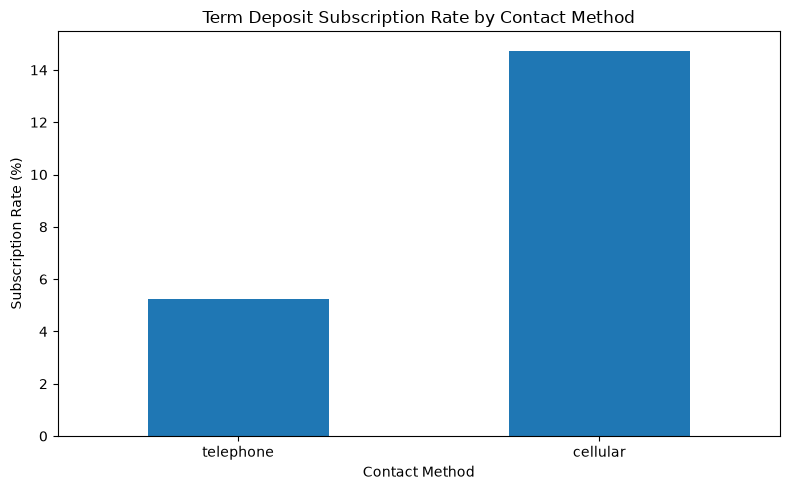

In [170]:
contact_success = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

contact_success["yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Term Deposit Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

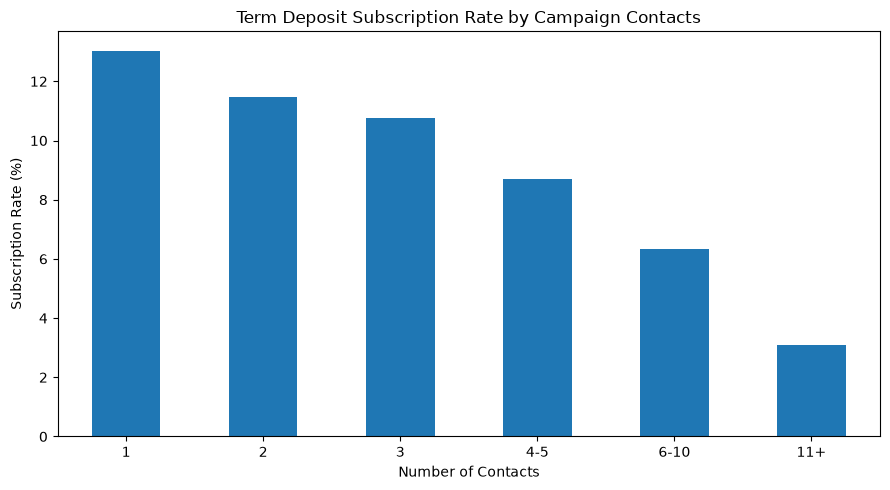

In [171]:
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, 100],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

campaign_success = pd.crosstab(
    df["campaign_group"],
    df["y"],
    normalize="index"
) * 100

campaign_success["yes"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Term Deposit Subscription Rate by Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

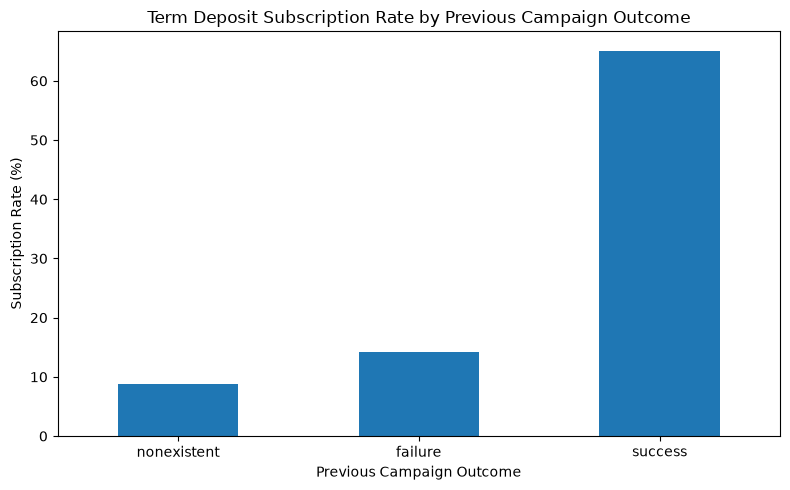

In [172]:
poutcome_success = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

poutcome_success["yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

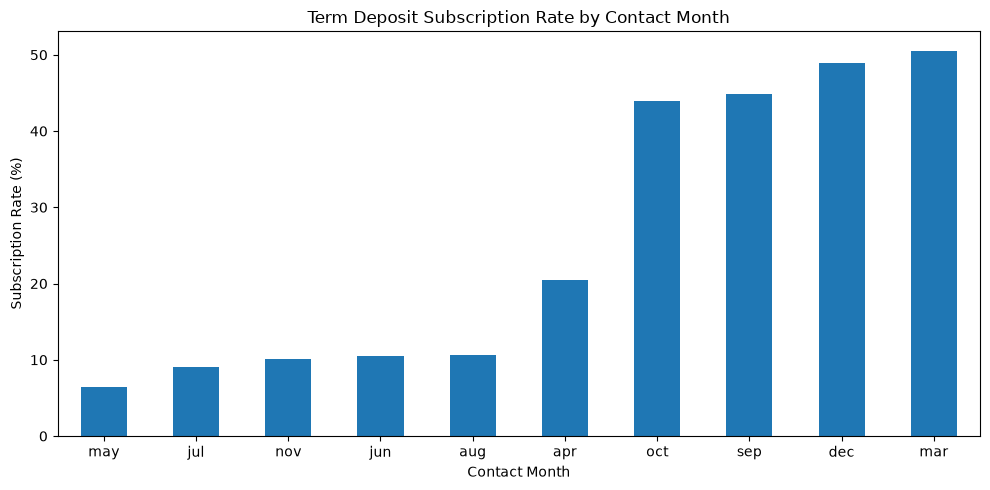

In [173]:
month_success = pd.crosstab(
    df["month"],
    df["y"],
    normalize="index"
) * 100

month_success["yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Term Deposit Subscription Rate by Contact Month")
plt.xlabel("Contact Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

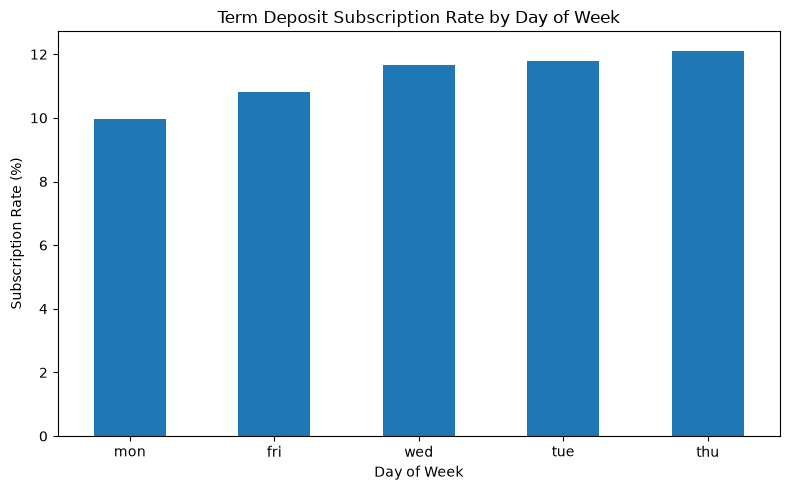

In [174]:
day_success = pd.crosstab(
    df["day_of_week"],
    df["y"],
    normalize="index"
) * 100

day_success["yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Term Deposit Subscription Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

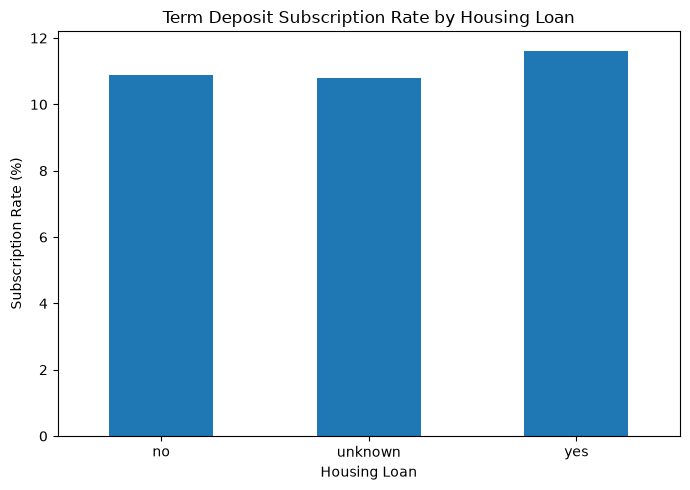

In [175]:
housing_success = pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

housing_success["yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Term Deposit Subscription Rate by Housing Loan")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

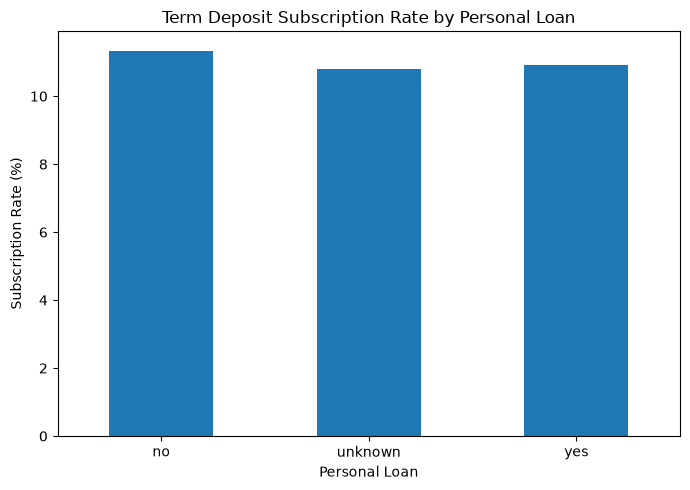

In [176]:
loan_success = pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

loan_success["yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Term Deposit Subscription Rate by Personal Loan")
plt.xlabel("Personal Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [177]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

correlation

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,-0.000808,0.004622,-0.034381,0.024379,-0.000242,0.001009,0.129075,0.010852,-0.017607
duration,-0.000808,1.000000,-0.071765,-0.047556,0.020600,-0.027941,0.005303,-0.008126,-0.032861,-0.044672
campaign,0.004622,-0.071765,1.000000,0.052606,-0.079182,0.150786,0.127826,-0.013657,0.135169,0.144129
pdays,-0.034381,-0.047556,0.052606,1.000000,-0.587508,0.271063,0.078920,-0.091374,0.296946,0.372659
previous,0.024379,0.020600,-0.079182,-0.587508,1.000000,-0.420587,-0.203197,-0.050929,-0.454571,-0.501411
emp.var.rate,-0.000242,-0.027941,0.150786,0.271063,-0.420587,1.000000,0.775293,0.196257,0.972244,0.906949
cons.price.idx,0.001009,0.005303,0.127826,0.078920,-0.203197,0.775293,1.000000,0.059170,0.688180,0.521945
cons.conf.idx,0.129075,-0.008126,-0.013657,-0.091374,-0.050929,0.196257,0.059170,1.000000,0.277864,0.100679
euribor3m,0.010852,-0.032861,0.135169,0.296946,-0.454571,0.972244,0.688180,0.277864,1.000000,0.945146
nr.employed,-0.017607,-0.044672,0.144129,0.372659,-0.501411,0.906949,0.521945,0.100679,0.945146,1.000000


In [178]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [179]:
import seaborn as sns
print("Seaborn:", sns.__version__)

Seaborn: 0.13.2


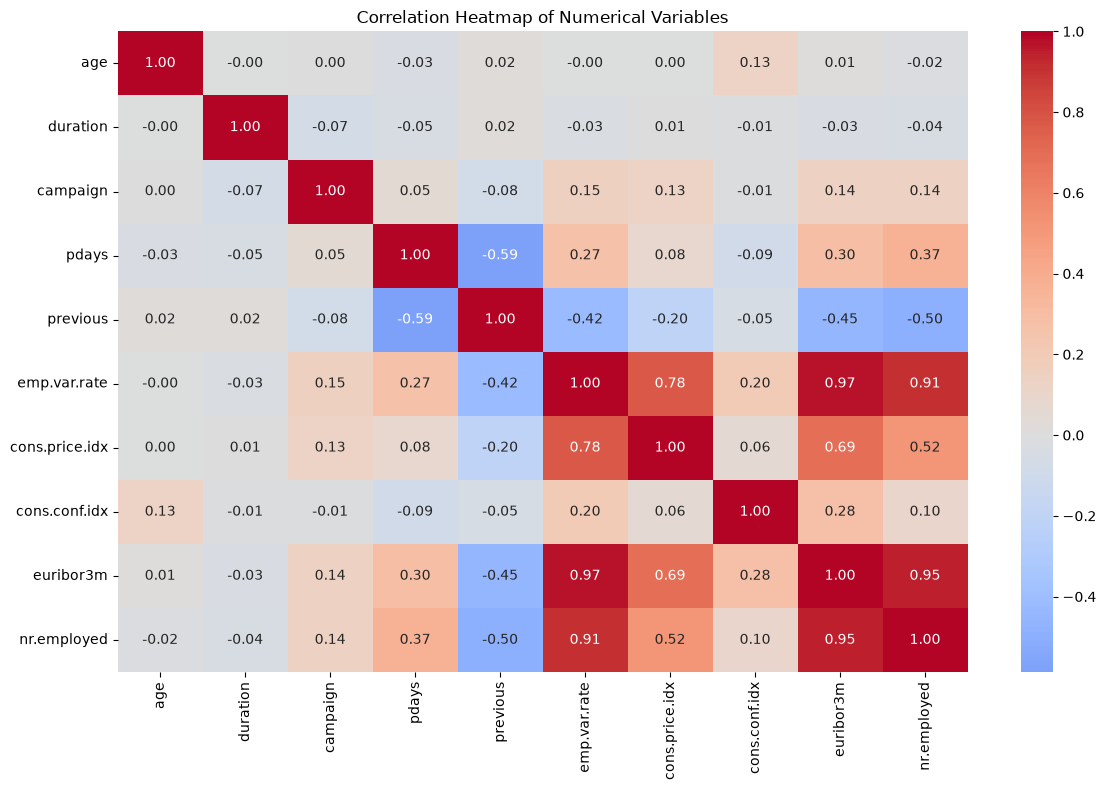

In [180]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [181]:
df["y"] = df["y"].map({
    "no": 0,
    "yes": 1
})

print(df["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


In [182]:
X = df.drop(columns=["y", "duration", "age_group", "campaign_group"])
y = df["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (41176, 19)
y shape: (41176,)


In [183]:
categorical_columns = X.select_dtypes(include="object").columns
numerical_columns = X.select_dtypes(exclude="object").columns

print("Categorical columns:")
print(list(categorical_columns))

print("\nNumerical columns:")
print(list(numerical_columns))

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical columns:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


C:\Users\hp\AppData\Local\Temp\ipykernel_20772\4027522151.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


In [184]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [185]:
import sklearn
print("Scikit-learn:", sklearn.__version__)

Scikit-learn: 1.9.1


In [186]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32940, 19)
X_test: (8236, 19)
y_train: (32940,)
y_test: (8236,)


In [187]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [188]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data processed:", X_train_processed.shape)
print("Testing data processed:", X_test_processed.shape)

Training data processed: (32940, 62)
Testing data processed: (8236, 62)


In [189]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [190]:
y_pred = logistic_model.predict(X_test_processed)

print("Predictions completed successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions completed successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [191]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Results
---------------------------
Accuracy : 0.8983
Precision: 0.65
Recall   : 0.2101
F1 Score : 0.3176

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7308
           1       0.65      0.21      0.32       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236

Confusion Matrix:
[[7203  105]
 [ 733  195]]


In [192]:
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

print(logistic_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.898251578436134, 'Precision': 0.65, 'Recall': 0.2101293103448276, 'F1 Score': 0.31758957654723124}


In [193]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=6
)

decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [194]:
y_pred_tree = decision_tree_model.predict(X_test_processed)

print("Decision Tree predictions completed successfully!")
print("First 10 predictions:", y_pred_tree[:10])

Decision Tree predictions completed successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [195]:
accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", round(accuracy_tree, 4))
print("Precision:", round(precision_tree, 4))
print("Recall   :", round(recall_tree, 4))
print("F1 Score :", round(f1_tree, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Decision Tree Results
---------------------
Accuracy : 0.9
Precision: 0.6548
Recall   : 0.2371
F1 Score : 0.3481

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7308
           1       0.65      0.24      0.35       928

    accuracy                           0.90      8236
   macro avg       0.78      0.61      0.65      8236
weighted avg       0.88      0.90      0.88      8236

Confusion Matrix:
[[7192  116]
 [ 708  220]]


In [196]:
tree_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_tree,
    "Precision": precision_tree,
    "Recall": recall_tree,
    "F1 Score": f1_tree
}

print(tree_results)

{'Model': 'Decision Tree', 'Accuracy': 0.8999514327343371, 'Precision': 0.6547619047619048, 'Recall': 0.23706896551724138, 'F1 Score': 0.34810126582278483}


In [197]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [198]:
y_pred_rf = random_forest_model.predict(X_test_processed)

print("Random Forest predictions completed successfully!")
print("First 10 predictions:", y_pred_rf[:10])

Random Forest predictions completed successfully!
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [199]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
---------------------
Accuracy : 0.893
Precision: 0.5483
Recall   : 0.2877
F1 Score : 0.3774

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7308
           1       0.55      0.29      0.38       928

    accuracy                           0.89      8236
   macro avg       0.73      0.63      0.66      8236
weighted avg       0.87      0.89      0.88      8236

Confusion Matrix:
[[7088  220]
 [ 661  267]]


In [200]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1 Score": f1_rf
}

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.8930305973773677, 'Precision': 0.5482546201232033, 'Recall': 0.28771551724137934, 'F1 Score': 0.3773851590106007}


In [201]:
model_results = pd.DataFrame([
    logistic_results,
    tree_results,
    rf_results
])

print(model_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.898252   0.650000  0.210129  0.317590
1        Decision Tree  0.899951   0.654762  0.237069  0.348101
2        Random Forest  0.893031   0.548255  0.287716  0.377385


In [202]:
model_results.to_csv(
    "../outputs/model_results.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


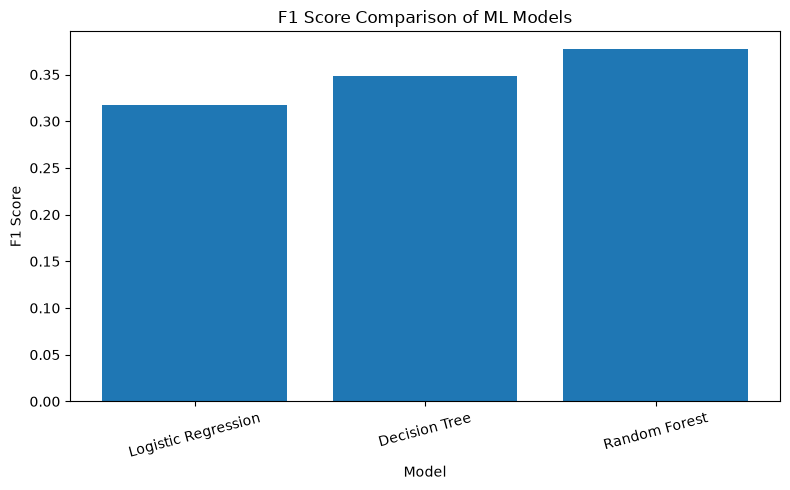

In [203]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["F1 Score"]
)

plt.title("F1 Score Comparison of ML Models")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

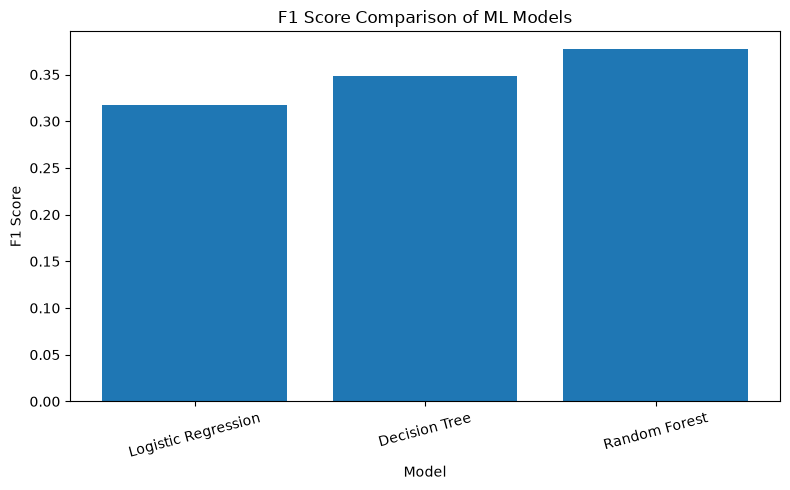

F1 score chart saved successfully!


In [204]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["F1 Score"]
)

plt.title("F1 Score Comparison of ML Models")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("../outputs/f1_score_comparison.png", dpi=300)
plt.show()

print("F1 score chart saved successfully!")

In [205]:

# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15))

Top 15 Important Features:
                             Feature  Importance
0                           num__age    0.158450
7                     num__euribor3m    0.117169
1                      num__campaign    0.080821
8                   num__nr.employed    0.047640
2                         num__pdays    0.029887
6                 num__cons.conf.idx    0.027001
4                  num__emp.var.rate    0.026838
61             cat__poutcome_success    0.026020
36                   cat__housing_no    0.021133
38                  cat__housing_yes    0.020727
5                num__cons.price.idx    0.020381
9                    cat__job_admin.    0.017668
22              cat__marital_married    0.016908
28        cat__education_high.school    0.016729
31  cat__education_university.degree    0.016388


In [206]:
feature_importance.to_csv(
    "../outputs/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [207]:
job_analysis = (
    df.groupby("job")["y"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

job_analysis["subscription_rate"] = job_analysis["mean"] * 100

job_analysis = job_analysis.sort_values(
    by="subscription_rate",
    ascending=False
)

job_analysis = job_analysis.drop(columns=["mean"])

print(job_analysis)

              job  count   sum  subscription_rate
8         student    875   275          31.428571
5         retired   1718   434          25.261932
10     unemployed   1014   144          14.201183
0          admin.  10419  1351          12.966695
4      management   2924   328          11.217510
11        unknown    330    37          11.212121
9      technician   6739   730          10.832468
6   self-employed   1421   149          10.485574
3       housemaid   1060   106          10.000000
2    entrepreneur   1456   124           8.516484
7        services   3967   323           8.142173
1     blue-collar   9253   638           6.895061


In [208]:
job_analysis.to_csv(
    "../outputs/job_subscription_analysis.csv",
    index=False
)

print("Job analysis saved successfully!")

Job analysis saved successfully!


In [209]:
import joblib

joblib.dump(
    random_forest_model,
    "../models/best_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [210]:
loaded_model = joblib.load("../models/best_model.pkl")

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Saved model loaded successfully!
Model type: RandomForestClassifier


## Conclusion

This project analyzed the Portuguese Bank Marketing dataset and developed machine learning models to predict whether a customer would subscribe to a term deposit.

Three classification models were evaluated:

- Logistic Regression
- Decision Tree
- Random Forest

The models were evaluated using Accuracy, Precision, Recall, and F1 Score.

Based on the test-set results, Random Forest achieved the highest Recall (28.77%) and F1 Score (37.74%) among the three tested models. Its Accuracy was 89.30% and Precision was 54.83%.

The Random Forest model was selected as the final model for this project and saved as `best_model.pkl`.

The analysis also identified customer and campaign-related variables that contributed to the model's predictions. These findings can help the bank marketing team use customer segmentation and predictive modeling as decision-support tools for future campaigns.

### Project Limitations

- The target variable is imbalanced, with substantially more customers who did not subscribe than customers who subscribed.
- Model performance may depend on the characteristics of the historical dataset.
- `duration` was excluded from the predictive model because it is known only after the call.
- Feature importance indicates which variables the model relied on; it does not establish causal relationships.

In [219]:
from sklearn.pipeline import Pipeline
import joblib

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", random_forest_model)
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [220]:
#joblib.dump(
#   final_pipeline,
#   "../models/best_model_pipeline.pkl")

#print("Complete model pipeline saved successfully!")


import os

print("Current folder:", os.getcwd())
print("Models folder exists:", os.path.exists("../models"))
print("Models folder path:", os.path.abspath("../models"))


Current folder: c:\Users\hp\OneDrive\Documents\Desktop\Portuguese_Bank_Marketing\notebooks
Models folder exists: True
Models folder path: c:\Users\hp\OneDrive\Documents\Desktop\Portuguese_Bank_Marketing\models


In [221]:

import os

test_path = os.path.abspath("../models/test.txt")

with open(test_path, "w") as f:
    f.write("Saving test successful")

print("Test file saved at:", test_path)


Test file saved at: c:\Users\hp\OneDrive\Documents\Desktop\Portuguese_Bank_Marketing\models\test.txt


In [222]:

import joblib
import os

model_path = os.path.abspath("../models/best_model_pipeline.pkl")

joblib.dump(final_pipeline, model_path)

print("Complete model pipeline saved successfully!")
print("Saved location:", model_path)


Complete model pipeline saved successfully!
Saved location: c:\Users\hp\OneDrive\Documents\Desktop\Portuguese_Bank_Marketing\models\best_model_pipeline.pkl


In [223]:
loaded_pipeline = joblib.load("../models/best_model_pipeline.pkl")

print("Pipeline loaded successfully!")
print("Pipeline steps:")
print(loaded_pipeline)

Pipeline loaded successfully!
Pipeline steps:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='str')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='str'))])),
                ('model', RandomForestClassifier(n_jobs=-1, random_state=42))])


In [224]:
# Test the saved pipeline on raw test data

pipeline_predictions = loaded_pipeline.predict(X_test)

print("Prediction test successful!")
print("Number of predictions:", len(pipeline_predictions))
print("First 10 predictions:", pipeline_predictions[:10])

Prediction test successful!
Number of predictions: 8236
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [225]:
print(model_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.898252   0.650000  0.210129  0.317590
1        Decision Tree  0.899951   0.654762  0.237069  0.348101
2        Random Forest  0.893031   0.548255  0.287716  0.377385


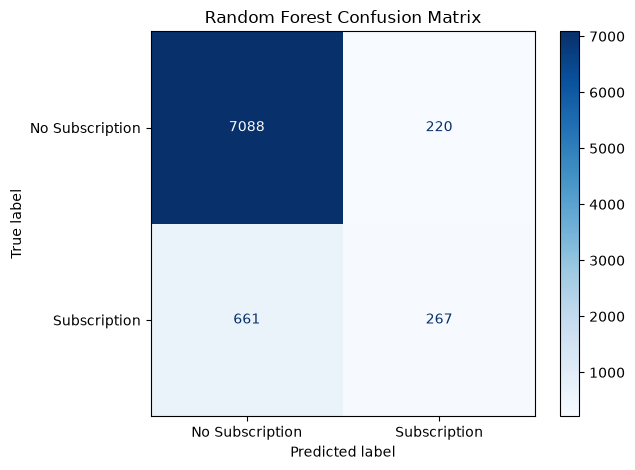

In [226]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No Subscription", "Subscription"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

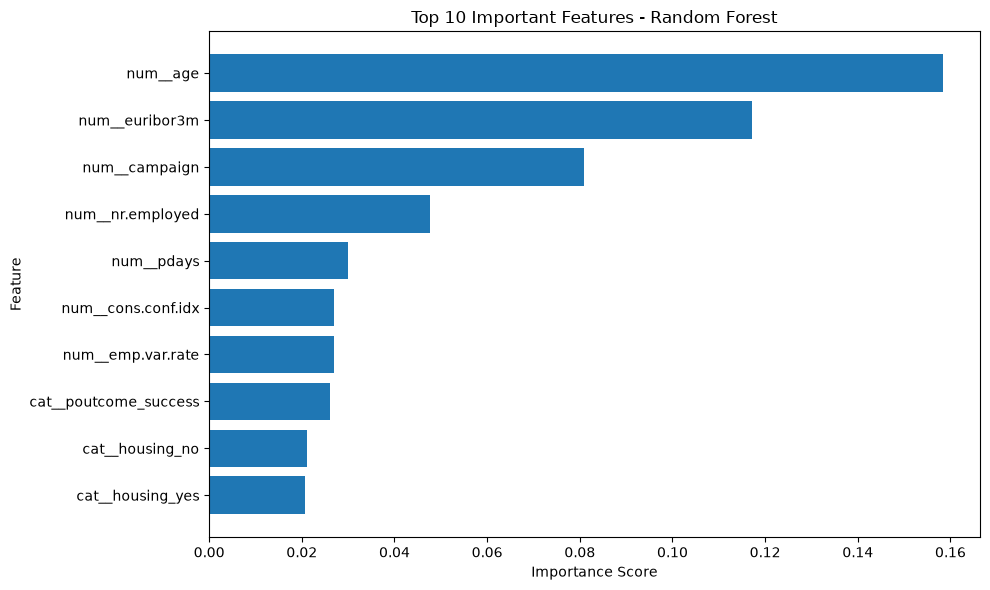

In [227]:

# Display the top 10 important features

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [228]:

import joblib
import os

model_path = os.path.abspath("../models/best_model_pipeline.pkl")

loaded_pipeline = joblib.load(model_path)

predictions = loaded_pipeline.predict(X_test)

print("Model loaded successfully!")
print("Total predictions:", len(predictions))
print("First 10 predictions:", predictions[:10])


Model loaded successfully!
Total predictions: 8236
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [229]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Model Accuracy:", round(accuracy_score(y_test, predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, target_names=["No Subscription", "Subscription"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))


Model Accuracy: 0.893

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.97      0.94      7308
   Subscription       0.55      0.29      0.38       928

       accuracy                           0.89      8236
      macro avg       0.73      0.63      0.66      8236
   weighted avg       0.87      0.89      0.88      8236


Confusion Matrix:
[[7088  220]
 [ 661  267]]


### Model Evaluation and Conclusion

The Random Forest model achieved an accuracy of 89.30%, a precision of 54.83%, a recall of 28.77%, and an F1-score of 0.3774.

The model correctly identified 267 customers who subscribed to a term deposit but missed 661 actual subscribers. This indicates that the model has room for improvement in identifying potential customers.

Among Logistic Regression, Decision Tree, and Random Forest, Random Forest achieved the highest F1-score. Therefore, it is selected as the current best-performing model based on this evaluation. However, further tuning, class-imbalance handling, and threshold optimization may improve its performance.

The model should be treated as a decision-support tool for marketing teams, not as a guarantee that a customer will subscribe.